# Predictive Performance and Fairness Analysis
### UCI Adult Income Dataset — Accuracy-Optimised Model

**Student:** Mpho Tlokotsi
**Student Number:** ST10408316
**Purpose:** This notebook supports Chapter 3 (Methodology) and Chapter 4 (Findings) of the Research Report. It builds a logistic regression model on the UCI Adult Income Dataset, evaluates its overall predictive performance, identifies the most influential features, and then evaluates fairness across gender and race groups.


The Adult dataset originates from the UCI Machine Learning Repository (Becker and Kohavi, 1996).


## Step 0 — Setup

Import all libraries up front and print their versions. Recording exact library versions supports the reproducibility argument made in Chapter 3 (Section 3.11) meaning that anyone re-running this notebook with the same versions should get the same results.


Documenting software versions supports reproducible computational research (Peng, 2011).


In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, roc_curve, classification_report, RocCurveDisplay
)

RANDOM_STATE = 42  # fixed seed for reproducibility (Chapter 3, Section 3.11)

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)


Python: 3.14.6
pandas: 3.0.3
scikit-learn: 1.9.0


## Step 1 — Load and Inspect the Dataset

**What this step does:** loads the UCI Adult Income Dataset and checks its shape, column types, and how balanced the target variable is.

**What it means for my research:** this operationalises Objective 1 (data preparation and exploration). The class-balance check matters because a very imbalanced target can inflate accuracy scores in a misleading way. It is worth noting explicitly in Chapter 4 if it applies here.

This cell reads the dataset from a **local file already uploaded to my JUPYTER notebook environment but is also available in the github repository**. 

The Adult dataset is widely used for classification and fairness evaluation (Becker and Kohavi, 1996).


In [2]:
COLUMN_NAMES = [
    "age", "workclass", "fnlwgt", "education", "education_num",
    "marital_status", "occupation", "relationship", "race", "sex",
    "capital_gain", "capital_loss", "hours_per_week", "native_country",
    "income",
]

# EDIT THIS if your uploaded file has a different name or location.
DATA_FILE = "adult.data"

# Files downloaded straight from UCI have no header row, so header=None + names=... is used.
# If your file already contains a header row, add `header=0` and remove `names=COLUMN_NAMES`.
df = pd.read_csv(DATA_FILE, header=None, names=COLUMN_NAMES,
                  sep=r",\s*", engine="python", na_values="?")

print(f"Loaded dataset from local file: {DATA_FILE}")
print("Shape:", df.shape)
df.head()


Loaded dataset from local file: adult.data
Shape: (32561, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [3]:
print(df.dtypes)
print()
print("Target class distribution:")
print(df["income"].value_counts(normalize=True).round(3))


age               int64
workclass           str
fnlwgt            int64
education           str
education_num     int64
marital_status      str
occupation          str
relationship        str
race                str
sex                 str
capital_gain      int64
capital_loss      int64
hours_per_week    int64
native_country      str
income              str
dtype: object

Target class distribution:
income
<=50K    0.759
>50K     0.241
Name: proportion, dtype: float64


## Step 2 — Clean and Preprocess the Data

**What this step does:** removes duplicate rows, handles missing values, and prepares predictors for modelling. Crucially, `sex` and `race` are set aside as a separate DataFrame for later fairness analysis and are **excluded from the model's predictors**.

**What it means for my research:** this is the decision, described in Chapter 3 (Section 3.5), that lets us test whether bias can still appear through *proxy variables* even when the sensitive attributes themselves are never given to the model, therefore, the stronger and more defensible version of your fairness claim.


**CORRECTION NOTE:** the original version of the next cell copied `sex` and `race` *before* dropping duplicates and then re-indexed them with the reset index, which attached demographic labels to the wrong records. The sensitive attributes are now extracted from the same cleaned table as the predictors and target, and an assertion checks the alignment. Overall model results are unchanged.


Excluding protected attributes does not necessarily remove discrimination because other variables may act as proxies (Barocas and Selbst, 2016).


In [4]:
# Step 2 (corrected): clean first, THEN extract the sensitive attributes
before = len(df)
df = df.drop_duplicates()
print(f"Removed {before - len(df)} duplicate rows.")

missing_mask = df.isna().any(axis=1)
print(f"Rows with missing values: {missing_mask.sum()} ({missing_mask.mean():.2%})")
df = df.loc[~missing_mask].reset_index(drop=True)   # single reset, after all cleaning
print(f"Remaining rows after removing missing values: {len(df)}")

# Sensitive attributes come from the SAME cleaned table as X and y
sensitive_attrs = df[["sex", "race"]].copy()
y = (df["income"].str.strip() == ">50K").astype(int)
X = df.drop(columns=["income", "sex", "race", "fnlwgt"])

# Integrity check: labels, predictors and target must be row-aligned
assert len(sensitive_attrs) == len(X) == len(y)
assert (sensitive_attrs.index == X.index).all()

numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = [c for c in X.columns if c not in numeric_cols]
print("Categorical columns:", categorical_cols)
print("Numeric columns:", numeric_cols)


Removed 24 duplicate rows.
Rows with missing values: 2398 (7.37%)
Remaining rows after removing missing values: 30139
Categorical columns: ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'native_country']
Numeric columns: ['age', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']


## Step 3 — Split into Training and Testing Sets

**What this step does:** splits the data (and the matching sensitive-attribute labels) into training and test sets using a fixed random seed, and builds a preprocessing pipeline (scaling + one-hot encoding) that is *fitted only on the training data*.

**What it means for my research:** this directly supports the reliability/validity argument in Chapter 3 that fitting preprocessing only on the training set avoids information leakage from the test set into the model.


Separating test data from model fitting helps prevent data leakage and optimistic performance estimates (Kaufman et al., 2012).


In [5]:
X_train, X_test, y_train, y_test, sens_train, sens_test = train_test_split(
    X, y, sensitive_attrs,
    test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
])

print("Training rows:", X_train.shape[0], " Test rows:", X_test.shape[0])


Training rows: 24111  Test rows: 6028


## Step 4 — Train the Logistic Regression Model

**What this step does:** fits a logistic regression model inside a pipeline (so preprocessing and modelling happen together, correctly, on every fold), and uses cross-validated grid search on the *training set only* to select the regularisation strength `C`.

**What it means for my research:** this operationalises the "accuracy-optimised model" described in Chapter 3 and the model is tuned purely to maximise predictive performance, with no fairness objective at all. That is the deliberate design choice my whole research question depends on.


Cross-validation supports model selection using training data, while regularisation controls model complexity (Hastie, Tibshirani and Friedman, 2009).


In [6]:
pipeline = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])

param_grid = {"model__C": [0.01, 0.1, 1, 10]}

grid_search = GridSearchCV(pipeline, param_grid, cv=5, scoring="accuracy", n_jobs=-1)
grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
print("Best C:", grid_search.best_params_["model__C"])
print("Best cross-validated training accuracy: {:.4f}".format(grid_search.best_score_))


Best C: 1
Best cross-validated training accuracy: 0.8475


## Step 5 — Evaluate Overall Predictive Performance

**What this step does:** generates predictions on the held-out test set and computes accuracy, precision, recall, F1-score, a confusion matrix, and ROC-AUC.

**What it means for my research:** this is the "is the model any good?" half of my main research question, and the numbers here go straight into Chapter 4 as my predictive-performance results. The metrics table below is styled for direct use as a Chapter 4 table/screenshot, and the ROC curve gives the ROC-AUC figure a visual it can be read alongside.


Precision, recall, F1 and ROC-AUC provide complementary assessments beyond accuracy (Fawcett, 2006; Sokolova and Lapalme, 2009).


In [7]:
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

overall_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1-score": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_proba),
}

overall_metrics_df = pd.DataFrame(overall_metrics.items(), columns=["Metric", "Value"])
overall_metrics_df["Value"] = overall_metrics_df["Value"].round(4)

print("Table 4.0: Overall Predictive Performance Metrics")
display(
    overall_metrics_df.style
        .format({"Value": "{:.4f}"})
        .bar(subset=["Value"], color="#2a6f7f", vmin=0, vmax=1)
        .hide(axis="index")
        .set_caption("Table 4.0: Overall Predictive Performance Metrics")
)

print()
print("Classification report:")
print(classification_report(y_test, y_pred, target_names=["<=50K", ">50K"]))


Table 4.0: Overall Predictive Performance Metrics


Metric,Value
Accuracy,0.8469
Precision,0.7334
Recall,0.6049
F1-score,0.6630
ROC-AUC,0.8992



Classification report:
              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.90      4527
        >50K       0.73      0.60      0.66      1501

    accuracy                           0.85      6028
   macro avg       0.80      0.77      0.78      6028
weighted avg       0.84      0.85      0.84      6028



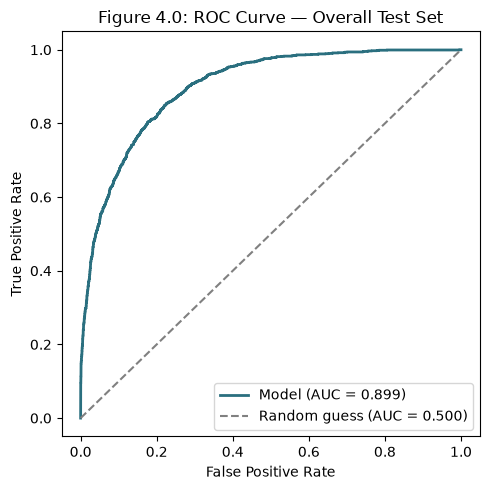

Saved: figure_4_0_roc_curve.png


In [8]:
# Figure 4.0 -- ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_proba)
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(fpr, tpr, color="#2a6f7f", linewidth=2,
        label=f"Model (AUC = {overall_metrics['ROC-AUC']:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random guess (AUC = 0.500)")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("Figure 4.0: ROC Curve — Overall Test Set")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("figure_4_0_roc_curve.png", dpi=200)
plt.show()
print("Saved: figure_4_0_roc_curve.png")


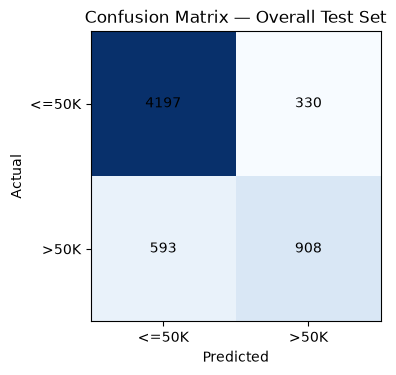

Saved: figure_4_1_confusion_matrix_overall.png


In [9]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_xticklabels(["<=50K", ">50K"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["<=50K", ">50K"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title("Confusion Matrix — Overall Test Set")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="black")
plt.tight_layout()
plt.savefig("figure_4_1_confusion_matrix_overall.png", dpi=200)
plt.show()
print("Saved: figure_4_1_confusion_matrix_overall.png")


## Step 6 — Extract Feature Importance

**What this step does:** pulls the logistic regression coefficients back out, maps them to their (one-hot-encoded) feature names, and ranks them by absolute size.

**What it means for my research:** this answers RQ1:which variables drive the model's predictions. we must look closely at any feature here that could act as a **proxy** for gender or race (e.g. `relationship`, `marital_status`, `occupation`) even though those attributes were never given to the model directly; that link is a key talking point for Chapter 4.


Logistic regression coefficients describe associations with the model prediction, not necessarily causal effects (Hastie, Tibshirani and Friedman, 2009).


Table 4.3: Top 15 Most Influential Features


feature,coefficient
num__capital_gain,2.3921
cat__occupation_Priv-house-serv,-1.4437
cat__marital_status_Married-civ-spouse,1.3659
cat__native_country_Columbia,-1.2628
cat__marital_status_Married-AF-spouse,1.1342
cat__relationship_Own-child,-1.1248
cat__occupation_Farming-fishing,-1.0864
cat__marital_status_Never-married,-1.0705
cat__native_country_South,-0.9513
cat__native_country_Dominican-Republic,-0.9445


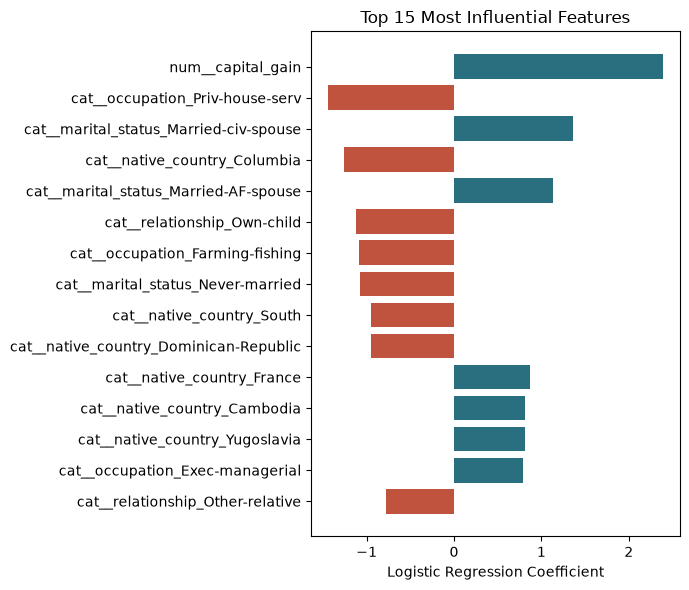

Saved: figure_4_2_feature_importance.png


In [10]:
feature_names = best_model.named_steps["preprocess"].get_feature_names_out()
coefficients = best_model.named_steps["model"].coef_[0]

importance_df = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients,
    "abs_coefficient": np.abs(coefficients),
}).sort_values("abs_coefficient", ascending=False).reset_index(drop=True)

top15 = importance_df.head(15)
print("Table 4.3: Top 15 Most Influential Features")
display(
    top15[["feature", "coefficient"]].style
        .format({"coefficient": "{:.4f}"})
        .bar(subset=["coefficient"], align="mid", color=["#c0533e", "#2a6f7f"])
        .hide(axis="index")
        .set_caption("Table 4.3: Top 15 Most Influential Features")
)

fig, ax = plt.subplots(figsize=(7, 6))
colors = ["#2a6f7f" if c > 0 else "#c0533e" for c in top15["coefficient"][::-1]]
ax.barh(top15["feature"][::-1], top15["coefficient"][::-1], color=colors)
ax.set_xlabel("Logistic Regression Coefficient")
ax.set_title("Top 15 Most Influential Features")
plt.tight_layout()
plt.savefig("figure_4_2_feature_importance.png", dpi=200)
plt.show()
print("Saved: figure_4_2_feature_importance.png")


## Step 7 — Compute Fairness Metrics by Group

**What this step does:** re-attaches the `sex` and `race` labels (kept aside in Step 2) to the test-set predictions, then computes, for each group:
- **Selection rate** — proportion predicted as `>50K` (used for demographic parity comparisons)
- **Disparate impact ratio** — the smaller group's selection rate divided by the larger/reference group's selection rate
- **True Positive Rate (TPR)** and **False Positive Rate (FPR)** — used for equalised-odds comparisons

**What it means for my research:** this directly answers RQ2 and is the fairness half of mu main research question. A helper function is defined once and reused for both `sex` and `race` so the analysis is consistent and easy to explain in Chapter 3. Rows below the 0.80 disparate-impact threshold are highlighted in red in the tables, and the bar charts that follow give the same information as an at-a-glance visual.

Demographic parity and equal opportunity capture different fairness criteria, which may not be simultaneously satisfied (Hardt, Price and Srebro, 2016). The four-fifths rule is a screening guideline for adverse impact, not definitive proof of unlawful discrimination (Equal Employment Opportunity Commission et al., 1978).


In [11]:
def fairness_table(y_true, y_pred, group_labels, reference_group):
    """Return a DataFrame of selection rate, TPR, FPR and disparate impact per group."""
    results = []
    for group in group_labels.unique():
        mask = (group_labels == group)
        yt, yp = y_true[mask], y_pred[mask]
        selection_rate = yp.mean()
        tp = ((yp == 1) & (yt == 1)).sum()
        fn = ((yp == 0) & (yt == 1)).sum()
        fp = ((yp == 1) & (yt == 0)).sum()
        tn = ((yp == 0) & (yt == 0)).sum()
        tpr = tp / (tp + fn) if (tp + fn) > 0 else np.nan
        fpr = fp / (fp + tn) if (fp + tn) > 0 else np.nan
        results.append({
            "group": group, "n": mask.sum(),
            "selection_rate": round(selection_rate, 4),
            "TPR": round(tpr, 4), "FPR": round(fpr, 4),
        })
    table = pd.DataFrame(results).sort_values("group").reset_index(drop=True)
    ref_rate = table.loc[table["group"] == reference_group, "selection_rate"].values[0]
    table["disparate_impact_ratio"] = (table["selection_rate"] / ref_rate).round(4)
    return table

def style_fairness_table(table, caption):
    """Colour rows below the 0.80 disparate-impact threshold in red for quick visual scanning."""
    def flag_row(row):
        colour = "background-color: #f8d7da" if row["disparate_impact_ratio"] < 0.80 else ""
        return [colour] * len(row)
    return (
        table.style
            .apply(flag_row, axis=1)
            .format({"selection_rate": "{:.4f}", "TPR": "{:.4f}", "FPR": "{:.4f}", "disparate_impact_ratio": "{:.4f}"})
            .hide(axis="index")
            .set_caption(caption)
    )

y_test_arr = y_test.reset_index(drop=True)
y_pred_arr = pd.Series(y_pred).reset_index(drop=True)
sens_test_arr = sens_test.reset_index(drop=True)

sex_fairness = fairness_table(y_test_arr, y_pred_arr, sens_test_arr["sex"], reference_group="Male")
race_fairness = fairness_table(y_test_arr, y_pred_arr, sens_test_arr["race"], reference_group="White")

print("Table 4.1: Fairness Metrics by Sex (reference group = Male)")
display(style_fairness_table(sex_fairness, "Table 4.1: Fairness Metrics by Sex"))

print()
print("Table 4.2: Fairness Metrics by Race (reference group = White)")
display(style_fairness_table(race_fairness, "Table 4.2: Fairness Metrics by Race"))


Table 4.1: Fairness Metrics by Sex (reference group = Male)


group,n,selection_rate,TPR,FPR,disparate_impact_ratio
Female,1956,0.0905,0.5498,0.0290,0.3473
Male,4072,0.2606,0.6150,0.0999,1.0000



Table 4.2: Fairness Metrics by Race (reference group = White)


group,n,selection_rate,TPR,FPR,disparate_impact_ratio
Amer-Indian-Eskimo,63,0.0794,0.3333,0.0526,0.3641
Asian-Pac-Islander,174,0.2586,0.6829,0.1278,1.1857
Black,594,0.1044,0.5122,0.0391,0.4787
Other,47,0.0638,0.5000,0.0233,0.2925
White,5150,0.2181,0.6096,0.0764,1.0000


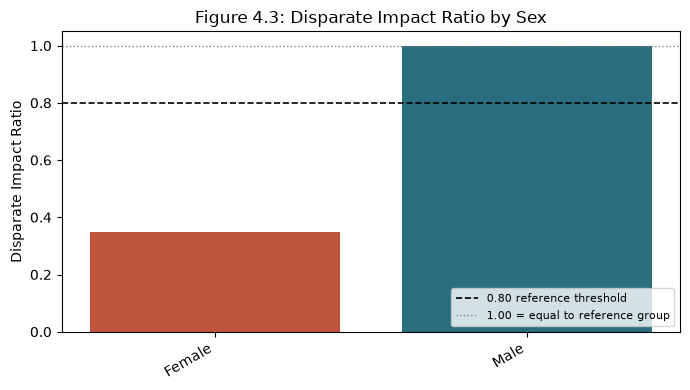

Saved: figure_4_3_disparate_impact_sex.png


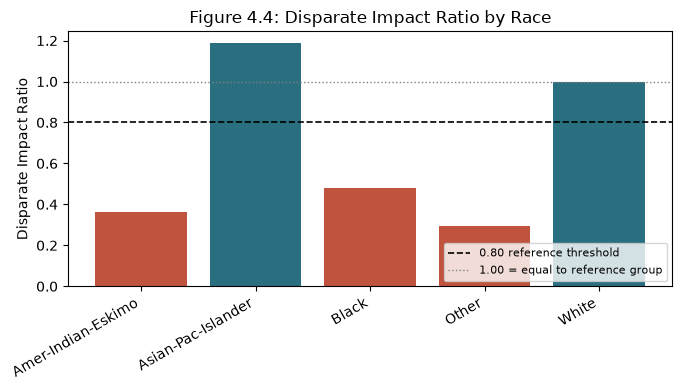

Saved: figure_4_4_disparate_impact_race.png


In [12]:
# Figure 4.3 and 4.4 -- Disparate Impact Ratio by group, with the 0.80 reference line
def plot_disparate_impact(table, title, filename):
    colors = ["#c0533e" if r < 0.80 else "#2a6f7f" for r in table["disparate_impact_ratio"]]
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(table["group"], table["disparate_impact_ratio"], color=colors)
    ax.axhline(0.80, color="black", linestyle="--", linewidth=1.2, label="0.80 reference threshold")
    ax.axhline(1.00, color="grey", linestyle=":", linewidth=1, label="1.00 = equal to reference group")
    ax.set_ylabel("Disparate Impact Ratio")
    ax.set_title(title)
    ax.legend(loc="lower right", fontsize=8)
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.savefig(filename, dpi=200)
    plt.show()
    print(f"Saved: {filename}")

plot_disparate_impact(sex_fairness, "Figure 4.3: Disparate Impact Ratio by Sex", "figure_4_3_disparate_impact_sex.png")
plot_disparate_impact(race_fairness, "Figure 4.4: Disparate Impact Ratio by Race", "figure_4_4_disparate_impact_race.png")


In [13]:
# Save fairness tables for direct use as tables in Chapter 4
sex_fairness.to_csv("table_4_1_fairness_by_sex.csv", index=False)
race_fairness.to_csv("table_4_2_fairness_by_race.csv", index=False)
print("Saved: table_4_1_fairness_by_sex.csv, table_4_2_fairness_by_race.csv")


Saved: table_4_1_fairness_by_sex.csv, table_4_2_fairness_by_race.csv


## Step 8 — Compare and Interpret the Results

**What this step does:** places the overall accuracy metrics (Step 5) next to the demographic-parity gaps and disparate-impact ratios (Step 7) in one summary table, and flags any group whose disparate impact ratio falls below the commonly cited 0.80 threshold.


Differences in accuracy and group fairness should be interpreted together rather than treating one metric as sufficient (Hardt, Price and Srebro, 2016).


In [14]:
print("=== SUMMARY ===")
print(f"Overall model accuracy: {overall_metrics['Accuracy']:.4f}")
print(f"Overall ROC-AUC: {overall_metrics['ROC-AUC']:.4f}")
print()

for label, table in [("Sex", sex_fairness), ("Race", race_fairness)]:
    flagged = table[table["disparate_impact_ratio"] < 0.80]
    if len(flagged):
        for _, row in flagged.iterrows():
            print(f"[FLAG] {label} group '{row['group']}' has a disparate impact ratio of "
                  f"{row['disparate_impact_ratio']:.2f} (below the 0.80 reference threshold), "
                  f"despite the model's overall accuracy of {overall_metrics['Accuracy']:.2%}.")
    else:
        print(f"No {label} group falls below the 0.80 disparate impact reference threshold.")


=== SUMMARY ===
Overall model accuracy: 0.8469
Overall ROC-AUC: 0.8992

[FLAG] Sex group 'Female' has a disparate impact ratio of 0.35 (below the 0.80 reference threshold), despite the model's overall accuracy of 84.69%.
[FLAG] Race group 'Amer-Indian-Eskimo' has a disparate impact ratio of 0.36 (below the 0.80 reference threshold), despite the model's overall accuracy of 84.69%.
[FLAG] Race group 'Black' has a disparate impact ratio of 0.48 (below the 0.80 reference threshold), despite the model's overall accuracy of 84.69%.
[FLAG] Race group 'Other' has a disparate impact ratio of 0.29 (below the 0.80 reference threshold), despite the model's overall accuracy of 84.69%.


## Step 9 — Supplementary analyses (added after supervisor feedback)

These cells produce the additional results reported in Section 4.6 of the Research Report: bootstrap intervals and extra fairness measures (Tables 4.5–4.7), permutation importance and category frequencies (Tables 4.9–4.10), the comparison of retained and excluded records (Table 4.11), the proxy-variable sensitivity analysis (Table 4.12) and the ten-split stability check (Table 4.13). Run them after Steps 0–8, from a clean kernel.

Bootstrap resampling can quantify uncertainty in estimated statistics (Efron and Tibshirani, 1993). Permutation importance evaluates changes in model performance after shuffling predictors (Breiman, 2001).


In [15]:
# 9.1 Bootstrap 95% intervals for disparate-impact ratios, parity / equal-opportunity differences, observed label rates
test = pd.DataFrame({"y": y_test_arr, "pred": y_pred_arr,
                     "sex": sens_test_arr["sex"], "race": sens_test_arr["race"]})
rng = np.random.default_rng(42); B = 2000; n = len(test)
def di(d, col, g, ref):
    return d[d[col] == g].pred.mean() / d[d[col] == ref].pred.mean()
ci = {}
for col, ref in [("sex", "Male"), ("race", "White")]:
    for g in test[col].unique():
        if g == ref: continue
        v = []
        for _ in range(B):
            s = test.iloc[rng.integers(0, n, n)]
            v.append(di(s, col, g, ref) if (s[col] == g).any() else np.nan)
        ci[f"{col}:{g}"] = np.round(np.nanpercentile(v, [2.5, 97.5]), 3)
print("95% bootstrap intervals for the disparate-impact ratio:"); 
for k, v in ci.items(): print(" ", k, v)

print("\nDemographic-parity (SPD) and equal-opportunity (EOD) differences:")
for col, ref in [("sex", "Male"), ("race", "White")]:
    r = test[test[col] == ref]; rs = r.pred.mean(); rt = r[r.y == 1].pred.mean()
    for g in test[col].unique():
        s = test[test[col] == g]
        print(f"  {col}:{g:20s} SPD={s.pred.mean()-rs:+.4f}  EOD={s[s.y==1].pred.mean()-rt:+.4f}")

full = df.copy(); full["y"] = y
print("\nObserved positive-label rate (all cleaned data) by sex and race:")
print(full.groupby("sex").y.agg(["mean", "size"]).round(4)); print(full.groupby("race").y.agg(["mean", "size"]).round(4))
print("Observed positive-label rate (test set):")
print(test.groupby("sex").y.mean().round(4).to_dict()); print(test.groupby("race").y.mean().round(4).to_dict())

95% bootstrap intervals for the disparate-impact ratio:
  sex:Female [0.298 0.401]
  race:Black [0.365 0.599]
  race:Other [0.    0.643]
  race:Asian-Pac-Islander [0.894 1.51 ]
  race:Amer-Indian-Eskimo [0.084 0.702]

Demographic-parity (SPD) and equal-opportunity (EOD) differences:
  sex:Male                 SPD=+0.0000  EOD=+0.0000
  sex:Female               SPD=-0.1701  EOD=-0.0652
  race:White                SPD=+0.0000  EOD=+0.0000
  race:Black                SPD=-0.1137  EOD=-0.0975
  race:Other                SPD=-0.1542  EOD=-0.1096
  race:Asian-Pac-Islander   SPD=+0.0406  EOD=+0.0733
  race:Amer-Indian-Eskimo   SPD=-0.1387  EOD=-0.2763

Observed positive-label rate (all cleaned data) by sex and race:
          mean   size
sex                  
Female  0.1138   9773
Male    0.3140  20366
                      mean   size
race                             
Amer-Indian-Eskimo  0.1189    286
Asian-Pac-Islander  0.2774    894
Black               0.1300   2816
Other               0.0

In [16]:
# 9.2 Permutation importance (original-variable level, held-out test set) and category frequencies
from sklearn.inspection import permutation_importance
pi = permutation_importance(best_model, X_test, y_test, scoring="accuracy",
                            n_repeats=20, random_state=RANDOM_STATE)
perm_df = pd.DataFrame({"variable": X_test.columns, "mean_decrease_accuracy": pi.importances_mean,
                        "sd": pi.importances_std}).sort_values("mean_decrease_accuracy", ascending=False)
print("Permutation importance (decrease in test accuracy when the variable is shuffled):")
display(perm_df.round(4).reset_index(drop=True))

rows = []
for f in importance_df.head(15).feature:
    if f.startswith("cat__"):
        k = f[5:]
        for c in categorical_cols:
            if k.startswith(c + "_"):
                v = k[len(c) + 1:]; m = (X_train[c] == v)
                rows.append((f, int(m.sum()), round(y_train[m].mean() * 100, 1)))
print("\nTraining-set size and share with income > 50K for categories with large coefficients:")
display(pd.DataFrame(rows, columns=["feature", "n_train", "pct_above_50K"]))

Permutation importance (decrease in test accuracy when the variable is shuffled):


,variable,mean_decrease_accuracy,sd
0,marital_status,0.0498,0.0031
1,capital_gain,0.0362,0.0017
2,education_num,0.0333,0.0018
3,occupation,0.0127,0.0026
4,relationship,0.0066,0.0019
5,hours_per_week,0.0053,0.0014
6,age,0.0046,0.0022
7,capital_loss,0.0034,0.0013
8,workclass,0.0017,0.0010
9,native_country,0.0006,0.0008



Training-set size and share with income > 50K for categories with large coefficients:


,feature,n_train,pct_above_50K
0,cat__occupation_Priv-house-serv,119,0.8
1,cat__marital_status_Married-civ-spouse,11233,45.6
2,cat__native_country_Columbia,47,4.3
3,cat__marital_status_Married-AF-spouse,17,41.2
4,cat__relationship_Own-child,3589,1.3
5,cat__occupation_Farming-fishing,786,10.3
6,cat__marital_status_Never-married,7769,4.7
7,cat__native_country_South,52,17.3
8,cat__native_country_Dominican-Republic,56,3.6
9,cat__native_country_France,22,50.0


In [17]:
# 9.3 Retained versus excluded (missing-value) records, after duplicate removal
raw = pd.read_csv(DATA_FILE, header=None, names=COLUMN_NAMES, sep=r",\s*", engine="python", na_values="?").drop_duplicates()
miss = raw.isna().any(axis=1)
excluded, retained = raw[miss], raw[~miss]
for c in ["sex", "race"]:
    print(pd.DataFrame({"excluded_n": excluded[c].value_counts(),
                        "excluded_%": (excluded[c].value_counts(normalize=True) * 100).round(2),
                        "retained_n": retained[c].value_counts(),
                        "retained_%": (retained[c].value_counts(normalize=True) * 100).round(2)}), "\n")
print("Share with income > 50K - excluded: {:.2f}%, retained: {:.2f}%".format(
      (excluded.income == ">50K").mean() * 100, (retained.income == ">50K").mean() * 100))

        excluded_n  excluded_%  retained_n  retained_%
sex                                                   
Male          1409       58.76       20366       67.57
Female         989       41.24        9773       32.43 

                    excluded_n  excluded_%  retained_n  retained_%
race                                                              
Amer-Indian-Eskimo          25        1.04         286        0.95
Asian-Pac-Islander         144        6.01         894        2.97
Black                      306       12.76        2816        9.34
Other                       40        1.67         231        0.77
White                     1883       78.52       25912       85.97 

Share with income > 50K - excluded: 13.89%, retained: 24.90%


In [18]:
# 9.4 Refit helper used for the proxy-variable sensitivity analysis and the multi-seed stability check
def run_model(drop=(), seed=RANDOM_STATE):
    Xv = df.drop(columns=["income", "sex", "race", "fnlwgt"] + list(drop))
    num = Xv.select_dtypes(include=np.number).columns.tolist(); cat = [c for c in Xv.columns if c not in num]
    Xtr, Xte, ytr, yte, s_tr, s_te = train_test_split(Xv, y, sensitive_attrs, test_size=0.2,
                                                       random_state=seed, stratify=y)
    pre = ColumnTransformer([("num", StandardScaler(), num),
                             ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
    gs = GridSearchCV(Pipeline([("preprocess", pre),
                                ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
                      {"model__C": [0.01, 0.1, 1, 10]}, cv=5, scoring="accuracy", n_jobs=-1).fit(Xtr, ytr)
    m = gs.best_estimator_; yp = m.predict(Xte); pr = m.predict_proba(Xte)[:, 1]
    s_te = s_te.reset_index(drop=True)
    sel = lambda col, grp: yp[(s_te[col] == grp).values].mean()
    out = {"C": gs.best_params_["model__C"], "accuracy": accuracy_score(yte, yp), "roc_auc": roc_auc_score(yte, pr),
           "sel_Female": sel("sex", "Female"), "sel_Male": sel("sex", "Male"),
           "DI_Female": sel("sex", "Female") / sel("sex", "Male")}
    for k, g in [("Black", "Black"), ("Other", "Other"), ("AmerIndianEskimo", "Amer-Indian-Eskimo"), ("AsianPacIslander", "Asian-Pac-Islander")]:
        out["DI_" + k] = sel("race", g) / sel("race", "White")
    return out

# 9.5 Proxy-variable sensitivity analysis (same split and grid search, selected variables removed)
variants = {"Full model": [], "Without relationship": ["relationship"], "Without marital_status": ["marital_status"],
            "Without relationship and marital_status": ["relationship", "marital_status"],
            "Without relationship, marital_status and occupation": ["relationship", "marital_status", "occupation"]}
ablation = pd.DataFrame({k: run_model(v) for k, v in variants.items()}).T
display(ablation.round(4))

,C,accuracy,roc_auc,sel_Female,sel_Male,DI_Female,DI_Black,DI_Other,DI_AmerIndianEskimo,DI_AsianPacIslander
Full model,1.0,0.8469,0.8992,0.0905,0.2606,0.3473,0.4787,0.2927,0.3640,1.1860
Without relationship,1.0,0.8475,0.8984,0.0700,0.2645,0.2648,0.4402,0.2980,0.3706,1.2612
Without marital_status,1.0,0.8479,0.8985,0.0900,0.2583,0.3483,0.4665,0.2948,0.4399,1.1680
Without relationship and marital_status,0.1,0.8129,0.8397,0.0930,0.1844,0.5045,0.4670,0.2566,0.3829,0.9358
"Without relationship, marital_status and occupation",1.0,0.8087,0.8257,0.0869,0.1793,0.4848,0.4324,0.2666,0.3978,1.1162


In [19]:
# 9.6 Stability across ten random train-test splits (seed 42 is the main analysis)
seed_df = pd.DataFrame([dict(run_model(seed=s), seed=s) for s in [42, 1, 2, 3, 4, 5, 6, 7, 8, 9]])
display(seed_df.round(4))
display(seed_df.drop(columns=["seed", "C"]).agg(["mean", "std", "min", "max"]).round(4).T)

,C,accuracy,roc_auc,sel_Female,sel_Male,DI_Female,DI_Black,DI_Other,DI_AmerIndianEskimo,DI_AsianPacIslander,seed
0,1.0,0.8469,0.8992,0.0905,0.2606,0.3473,0.4787,0.2927,0.3640,1.1860,42
1,0.1,0.8494,0.9070,0.0775,0.2606,0.2972,0.3869,0.5108,0.6220,1.2614,1
2,10.0,0.8441,0.9004,0.0861,0.2705,0.3183,0.4313,0.3750,0.4407,1.0114,2
3,1.0,0.8437,0.9009,0.0769,0.2697,0.2851,0.4706,0.3730,0.2492,1.1247,3
4,10.0,0.8431,0.8979,0.0764,0.2622,0.2915,0.3975,0.3165,0.3504,1.3019,4
5,1.0,0.8426,0.8998,0.0890,0.2687,0.3312,0.4151,0.4010,0.5205,1.3956,5
6,0.1,0.8449,0.9019,0.0763,0.2560,0.2979,0.3981,0.2293,0.5140,0.7833,6
7,1.0,0.8442,0.8987,0.0892,0.2600,0.3431,0.4381,0.2100,0.4400,1.2429,7
8,1.0,0.8525,0.9073,0.0768,0.2621,0.2932,0.4509,0.0000,0.4681,1.3003,8
9,10.0,0.8504,0.9096,0.0839,0.2570,0.3265,0.4117,0.4478,0.3854,1.2917,9


,mean,std,min,max
accuracy,0.8462,0.0034,0.8426,0.8525
roc_auc,0.9023,0.0041,0.8979,0.9096
sel_Female,0.0823,0.0061,0.0763,0.0905
sel_Male,0.2627,0.0052,0.2560,0.2705
DI_Female,0.3131,0.0229,0.2851,0.3473
DI_Black,0.4279,0.0316,0.3869,0.4787
DI_Other,0.3156,0.1447,0.0000,0.5108
DI_AmerIndianEskimo,0.4354,0.1048,0.2492,0.6220
DI_AsianPacIslander,1.1899,0.1785,0.7833,1.3956


## References 

Barocas, S. and Selbst, A.D. 2016. Big data’s disparate impact. *California Law Review*, 104(3):671–732. Available at: https://doi.org/10.15779/Z38BG31 [Accessed 4 November 2026].

Becker, B. and Kohavi, R. 1996. *Adult*. UCI Machine Learning Repository. Available at: https://doi.org/10.24432/C5XW20 [Accessed 4 November 2026].

Breiman, L. 2001. Random forests. *Machine Learning*, 45:5–32. Available at: https://doi.org/10.1023/A:1010933404324 [Accessed 4 November 2026].

Efron, B. and Tibshirani, R.J. 1993. *An introduction to the bootstrap*. New York: Chapman & Hall.

Equal Employment Opportunity Commission, Civil Service Commission, Department of Labor and Department of Justice. 1978. Uniform guidelines on employee selection procedures. *Federal Register*, 43(166):38290–38315. Available at: https://www.eeoc.gov/laws/guidance/uniform-guidelines-employee-selection-procedures [Accessed 4 November 2026].

Fawcett, T. 2006. An introduction to ROC analysis. *Pattern Recognition Letters*, 27(8):861–874. Available at: https://doi.org/10.1016/j.patrec.2005.10.010 [Accessed 4 November 2026].

Hardt, M., Price, E. and Srebro, N. 2016. Equality of opportunity in supervised learning. In: *Advances in Neural Information Processing Systems 29*. Available at: https://arxiv.org/abs/1610.02413 [Accessed 4 November 2026].

Hastie, T., Tibshirani, R. and Friedman, J. 2009. *The elements of statistical learning: data mining, inference, and prediction*. 2nd ed. New York: Springer. Available at: https://doi.org/10.1007/978-0-387-84858-7 [Accessed 4 November 2026].

Kaufman, S., Rosset, S., Perlich, C. and Stitelman, O. 2012. Leakage in data mining: formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data*, 6(4):1–21. Available at: https://doi.org/10.1145/2382577.2382579 [Accessed 4 November 2026].

Peng, R.D. 2011. Reproducible research in computational science. *Science*, 334(6060):1226–1227. Available at: https://doi.org/10.1126/science.1213847 [Accessed 4 November 2026].

Sokolova, M. and Lapalme, G. 2009. A systematic analysis of performance measures for classification tasks. *Information Processing & Management*, 45(4):427–437. Available at: https://doi.org/10.1016/j.ipm.2009.03.002 [Accessed 4 November 2026].
